# camelyon17: real-record counterexample

The question is whether a static epistemic summary characterizes which additional information is useful. This notebook uses genuine images, recorded domains and recorded target labels. It never manufactures domains from target classes. It reports negative outcomes without changing matching criteria.

This is a reproducible pilot with a **custom group-disjoint split**, not a completed CVPR benchmark. All outputs, observations, model states, figures, sources and an executed notebook are saved beneath `workbook/camelyon17_counterexample_<UTC>/`. Run the notebook using the `reach-aistats` environment or `scripts/run_wilds_notebook.py`.


## Sources and what each contributes

- Koh et al., [WILDS (ICML 2021)](https://arxiv.org/abs/2012.07421), [dataset descriptions](https://wilds.stanford.edu/datasets/): source/domain meaning and benchmark provenance. Our group split is custom; our numbers are not official WILDS benchmark scores.
- Bandi et al., [CAMELYON17](https://doi.org/10.1109/TMI.2018.2867350): tumor and hospital annotations. [WILDS loader](https://github.com/p-lambda/wilds/blob/main/wilds/datasets/camelyon17_dataset.py) documents patient/slide fields and hospital numbering.
- Christie et al., [Functional Map of the World (CVPR 2018)](https://openaccess.thecvf.com/content_cvpr_2018/html/Christie_Functional_Map_of_CVPR_2018_paper.html), [WILDS loader](https://github.com/p-lambda/wilds/blob/main/wilds/datasets/fmow_dataset.py): land-use classes, region and temporal metadata.
- [Camelyon public mirror](https://huggingface.co/datasets/wltjr1007/Camelyon17-WILDS), revision `d784d5344ba6c967f83f9f3d9b2f1e2a4d6eb78f`; [FMoW mirror](https://huggingface.co/datasets/danielz01/fMoW), revision `8a27a7988a20341352b85bf0e65e88a6c1337f1c`: transport alternatives. These are third-party mirrors, not independently verified official copies. The adapter also accepts official local WILDS folders. The original server failed certificate verification; FMoW mirror requires user access.
- Hüllermeier & Waegeman, [uncertainty concepts](https://doi.org/10.1007/s10994-021-05946-3): distinguish uncertainty about predictions from stochastic outcomes. We do not estimate aleatoric uncertainty here.
- Gal & Ghahramani, [MC dropout (ICML 2016)](https://proceedings.mlr.press/v48/gal16.html): sampled predictive distributions. Finite sample extrema are not confidence bounds on the true probability.
- [DAPPr paper](https://arxiv.org/abs/2605.00600) and [loss implementation](https://github.com/MaxwellYaoNi/DAPPr/blob/main/DAPPr.py): baseline loss and scalar K/sum(alpha). We adapt the head/encoder and schedule, not reproduce the original architecture/training.
- [Probly](https://github.com/pwhofman/probly): actual sampler, representation and quantification interfaces. Installed version is saved. Our existing adapter exposes probability endpoints and labels their semantics.
- Hoeffding, [Probability Inequalities (1963)](https://doi.org/10.1080/01621459.1963.10500830): frequency boxes for bounded independent empirical-population draws; union bound allocates error over boxes. This is not an iid-patch guarantee across new patients.
- Charnes & Cooper, [linear fractional programming (1962)](https://doi.org/10.1002/nav.3800090303): sharp ratio extrema over the declared linear joint-mass set.
- Local `acquisition_counterexample.ipynb`, `real/beta_acquisition.py`, `real/source_acquisition.py`: exact toy proof, Beta conjugacy, total-variance action values and joint-mass implementation. Beta conjugacy follows directly by multiplying a Bernoulli likelihood by a Beta density. All new code is archived in each run.

- He et al., [Deep Residual Learning (CVPR 2016)](https://openaccess.thecvf.com/content_cvpr_2016/html/He_Deep_Residual_Learning_CVPR_2016_paper.html), [torchvision ResNet18](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html): frozen encoder and preprocessing. [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html): finite-cell quantization.


## 1. Freeze the protocol before looking at results

Camelyon uses known hospitals **0 and 3**, candidate hospital **2**, and tumor=1. FMoW uses known regions **Americas and Europe**, candidate **Asia**, and retains full class labels for classification. For the binary prevalence/label-bound target, FMoW uses the modal training class with a deterministic label tie-break, frozen before evaluating held-out labels.

Split groups by a seeded hash of identities only: approximately 60% fit, 20% reference, 20% evaluation per source. A Camelyon patient is a group; an FMoW location rounded to 0.01 degrees is a conservative spatial group. All repeated images within a group stay together. Small numbers of held-out patients are explicitly counted; image counts do not imply equally many independent patients.

For FMoW, this pilot uses observations before 2016; later years are retained in the record audit but excluded from the current experiments. Thus the completed experiment concerns region shift, not a validated temporal-shift result. We preserve original split fields for audit, but deliberately do not claim the official WILDS split: a source-identity acquisition comparison requires both known sources in the evaluation mixture.


In [1]:
# Goal: save a fixed configuration and create a fresh output directory.
from pathlib import Path
import os,sys,json,shutil,hashlib,importlib.metadata
import numpy as np
import pandas as pd
from IPython.display import display,Markdown,Image
ROOT=Path.cwd()
if not (ROOT/'real/wilds_records.py').exists():
    ROOT=ROOT/'Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS'
sys.path.insert(0,str(ROOT))
DATASET='camelyon17'
KIND='counterexample'
DATA_ROOT=Path(os.environ.get('WILDS_DATA_ROOT',str(ROOT/'data/wilds/camelyon17-mirror')))
WEIGHTS=Path(os.environ.get('WILDS_ENCODER_WEIGHTS',str(ROOT/'data/wilds/resnet18-f37072fd.pth')))
SEED=20261030
RUN_DIR=ROOT/'workbook'/('camelyon17_counterexample_'+pd.Timestamp.now(tz='UTC').strftime('%Y%m%dT%H%M%S%fZ'))
RUN_DIR.mkdir(parents=True,exist_ok=False)
protocol=dict(dataset=DATASET,kind=KIND,seed=SEED,data_root=str(DATA_ROOT),image_cap_per_role_source=2000,
    epochs=30,mc_passes=30,cells=4,acquisition_repeats=5,group_split='60/20/20 fit/reference/evaluation',
    fmow_years='before 2016; later years excluded',mi_match_relative_tolerance=.01,action_margin=2)
(RUN_DIR/'protocol.json').write_text(json.dumps(protocol,indent=2))
source_nb=json.loads((ROOT/'camelyon17_counterexample.ipynb').read_text())
(RUN_DIR/'SOURCES.md').write_text(''.join(source_nb['cells'][1]['source']))
print('Outputs:',RUN_DIR)


Outputs: /home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/camelyon17_counterexample_20261030T092024988890Z


## 2. Read recorded fields and enforce leakage checks

The adapter supports official WILDS files and complete parquet splits from the listed mirrors. Missing fields, incomplete shards, missing source groups and non-unique record IDs are errors. Every selected row keeps its file/row or original image path. Labels do not determine the patient/location partition.

The empirical population is the retained dataset, not a national population, a hospital's clinical prevalence, or all global satellite imagery. Later resampling with replacement estimates behavior conditional on these records; it does not generate new independent patients or locations.


In [2]:
# Goal: audit source/group counts and persist the full partition before fitting or searching.
from real.wilds_records import read_records,group_partition,image_sample,save_data_audit
records=group_partition(read_records(DATASET,DATA_ROOT),SEED)
save_data_audit(records,DATA_ROOT,RUN_DIR,DATASET)
display(records.groupby(['source_name','role']).agg(records=('record_id','size'),groups=('group','nunique')))
assert records.groupby('group').role.nunique().max()==1


records  groups
source_name role                       
0           evaluation    13637       1
            fit           26940       5
            reference     18859       1
2           evaluation     4556       1
            fit           67756       7
            reference     12742       1
3           evaluation    21284       2
            fit           98515       6
            reference     10039       2

## 3. Same estimand and uncertainty score; different observation channels

This counterexample models **population target prevalence**, not an individual image conditional probability. It uses recorded source and target fields, without conditioning on image pixels. The companion image notebook tests visual representations separately; we must not call this a neural-model counterexample.

Let $W=P(S=1)$, $\Theta_s=P(Y=1\mid S=s)$ and $T=(1-W)\Theta_0+W\Theta_1$. Independent Beta(1,1) priors are updated using recorded observations. If $m_j,v_j$ are component means/variances, then

$$E[T]=(1-m_w)m_0+m_wm_1,$$
$$\operatorname{Var}(T)=((1-m_w)^2+v_w)v_0+(m_w^2+v_w)v_1+v_w(m_1-m_0)^2.$$

Conventional predictive epistemic MI is $h(E[T])-E[h(T)]$, integrated by Gauss–Jacobi quadrature, checked at twice the order and independently with Probly posterior samples. It correctly measures predictive disagreement under this model.

Acquiring one random **source identity** updates W. Acquiring one **source-stratified target label** chooses source 0 or 1 with equal probability and updates its Theta. Equal cost is an explicit assumption. The law of total variance gives their one-step Bayes squared-error reductions:

$$V_{ID}=(m_1-m_0)^2v_w/(a_w+b_w+1),$$
$$V_{label}=\tfrac12[(1-m_w)^2v_0/(a_0+b_0+1)+m_w^2v_1/(a_1+b_1+1)].$$

Different values can coexist with similar predictive MI because the channels reveal different parameters. This does not refute MI or Bayesian updating. It tests the sufficiency of a static summary for acquisition choice.

Scan 600 training information states: identity budgets 0,2,8,32,128,512; labels per known source 2,8,32,128,512; 20 repetitions. Require MI difference <=1%, mean difference <=0.02, variance difference <=10%, opposite action preference with >=2x margin. Select smallest MI discrepancy; never select on held-out outcomes. No match is a saved negative result.

For a selected pair, enumerate held-out outcome frequencies to compare actual expected squared error against the same held-out prevalence. **Both opposite advantages must be positive** for confirmation. Save 2,000 paired acquisition trajectories and record IDs. The Monte Carlo standard error describes this resampling experiment only.

Also save a 95% posterior credible enclosure for T by bounding each Beta component and evaluating all box vertices. This is neither a support/identification interval (the Beta support remains [0,1]) nor an interval of epistemic MI. Static bounds alone do not supply acquisition likelihoods.


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.


findfont: Failed to find font weight 300 for STIXGeneral, now using 400.


... (833 outputs left out)

findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


findfont: Generic family 'sans-serif' not found because none of the following families were found: Fira Sans


# Real-record counterexample

{
  "status": "evaluated",
  "candidates": 600,
  "matches": 39,
  "mi_relative_difference": 0.0001700092095866356,
  "identity_advantage": 0.0006123457784492983,
  "label_advantage": 0.0005553662645885679,
  "confirmed": true
}

A selected near-match under a declared Beta model, not an exact equality proof. Both held-out advantages must be positive for confirmation. Target is population prevalence, not per-image prediction. Images are not conditioned on in this counterexample. Acquisitions resample genuine fields from fixed empirical populations; uncertainty bars are not patient-population confidence intervals. Neither DAPPr failure nor sufficiency of static probability bounds follows.


,state_id,n_identity,n_labels_per_source,mean,variance,mi,value_identity,value_label,shapes,role,mi_order48
0,390,32,512,0.578622,0.001172,0.002407,2.569923e-05,2.610674e-07,"[[26.0, 8.0], [133.0, 381.0], [348.0, 166.0]]",identity_preferred,0.002407
1,566,512,128,0.578479,0.001172,0.002407,9.443666e-08,4.282366e-06,"[[403.0, 111.0], [36.0, 94.0], [86.0, 44.0]]",label_preferred,0.002407


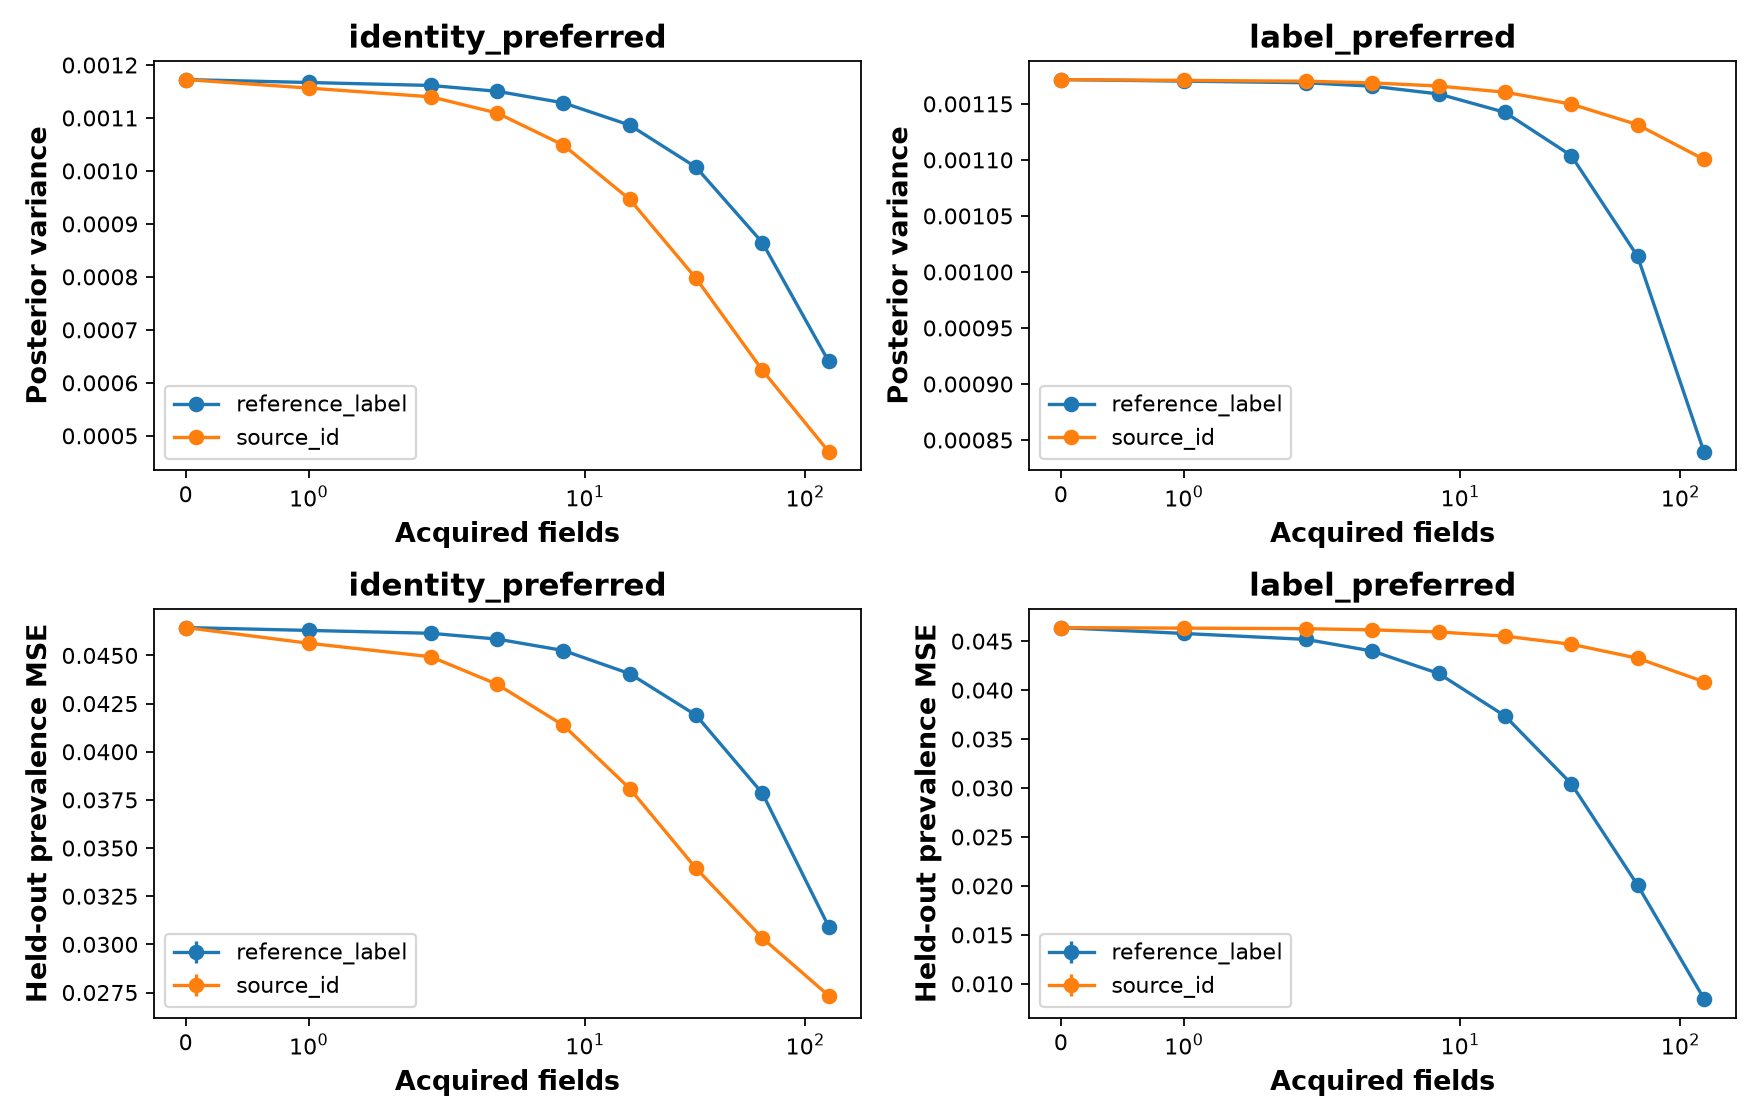

In [3]:
# Goal: run the frozen search, held-out endpoint, probability enclosure and paired acquisition sweeps.
from real.wilds_counterexample import run_counterexample
result=run_counterexample(records,RUN_DIR,seed=SEED)
display(Markdown((RUN_DIR/'RESULTS.md').read_text()))
if (RUN_DIR/'selected_states.csv').exists():display(pd.read_csv(RUN_DIR/'selected_states.csv'))
if (RUN_DIR/'acquisition_curves.png').exists():display(Image(filename=str(RUN_DIR/'acquisition_curves.png')))


## 6. Preserve the experiment and its limitations

Save source code snapshots and package versions. The runner adds the executed notebook, execution status and SHA-256 artifact manifest even if execution fails. Negative counterexample outcomes remain negative; wide or empty intervals remain visible. No run is described as a successful paper-level result solely because code executed.


In [4]:
# Goal: archive the exact local implementations used for this run.
for path in list((ROOT/'real').glob('wilds_*.py'))+[ROOT/'real/beta_acquisition.py',ROOT/'real/source_acquisition.py',ROOT/'real/probability_bounds.py',ROOT/'scripts/build_wilds_notebooks.py']:
    shutil.copy2(path,RUN_DIR/path.name)
shutil.copy2(ROOT/'camelyon17_counterexample.ipynb',RUN_DIR/'source_notebook.ipynb')
(RUN_DIR/'versions.json').write_text(json.dumps({p:importlib.metadata.version(p) for p in ['numpy','scipy','pandas','torch','torchvision','probly','pyarrow','scikit-learn']},indent=2))
print('Saved results:',RUN_DIR)


Saved results: /home/mtleao/projects/Concept_Disentaglement/Uncertainty_Modeling/EU_AU_Disentanglement/REACH_AISTATS/workbook/camelyon17_counterexample_20261030T092024988890Z
